# 🧪 LAB: Non-linear Dimensionality Reduction — t-SNE and UMAP

Over the past few weeks, we have explored how to handle non-linear relationships, mainly in the context of classification and regression tasks.

However, sometimes the first and most important step is to **visualize** the data — to gain intuition, spot structure, or detect outliers — even before any predictive modeling. You have already seen how PCA can help with this, but as we discussed this week, (ordinary) PCA is a linear method and may not capture non-linear patterns in the data effectively.

In this lab, you will learn about two popular **non-linear dimensionality reduction techniques** that are typically used for **data visualization**:  
- **t-SNE (t-distributed Stochastic Neighbor Embedding)**  
- **UMAP (Uniform Manifold Approximation and Projection)**

You will apply and compare these methods on two datasets:
- A simple biological dataset: Palmer Penguins
- A high-dimensional human genotype dataset from the 1000 Genomes Project (adapted from Diaz-Papkovich *et al.*, 2019)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


In [ ]:
NAME(s) = "Kavan W., Michelle J., Max G."

## 1. Background Reading (20 points)

Begin by reading **Section 5.3: t-SNE and UMAP for High-Dimensional Data** from the [*Machine Learning Hero* book](https://www.oreilly.com/library/view/machine-learning-hero/9781837025015/), which is available through UVA’s subscription to O’Reilly.

After reading, discuss with your group and respond to the following questions:

a. **Why might we choose t-SNE or UMAP over PCA for dimensionality reduction?**  
Briefly explain the limitations of PCA, and why non-linear methods like t-SNE and UMAP can be more effective in some contexts.

b. **Summarize the strengths and weaknesses of t-SNE and UMAP.**  
What are the key differences between the two methods? In what situations might you prefer one over the other?

c. **What are the main hyperparameters of each method, and what role do they play?**  
Describe how these hyperparameters affect the behavior and output of the algorithms.


**ANSWER:**

a. PCA is a linear dimensionsality reduction method, which means that it may fail to capture complex, non-linear realtionships. Both t-SNE and UMAP are non-linear methods that are better at preserving relationships between similar observations. This means that they may reveal clusters or patterns that PCA could miss.

b. t-SNE is good at visualizing high-dimensional datasets and preserving the local structure of the data. That said, it can be computationally expensive, and it doesn't preserve gloabl realationships well. UMAP is faster, it works better with larger datasets, and it tends to preserve both local and global structure better than t-SNE. So, t-SNE may be preferable when the main priority is visualizing local clusters in smaller datasets and UMAP may be preferable for larger datasets or when broader structure is important.

c. For t-SNE, the main hyperparameter is perplexity, which controls the effective size of the nerighborhood that is considered around each point. Lower values of perplexity emphasize more local structure, whereas higher values of perplexity consider broader relationships. Additionally, both learning rate and number of iterations also affect the optimization. For UMAP, the main hyperparameter are n_neighbors and min_dist. n_neighbors controls the balance between local and global structure. Smaller values of n_neighbors emphasize local relationships and larger values of n_dist emphasize broader structure. min_dist controls how tightly points can cluster. Smaller values of min_dist make more compact clusters and larger values of min_dist make more spread-out projections.

## 2. Experiment with the Palmer Penguins Dataset (Toy Example) (50 points)

To get hands-on experience, you will begin by applying dimensionality reduction techniques to a small and interpretable dataset: Palmer Penguins.

Before you begin coding, read the official documentation for the following methods:

- [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) — from `sklearn.decomposition`
- [t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) — from `sklearn.manifold`
- [UMAP](https://umap-learn.readthedocs.io/en/latest/basic_usage.html) — from the `umap-learn` package

After reviewing the documentation, complete the following tasks:

a. Load the Palmer Penguins dataset as demonstrated in the [UMAP documentation](https://umap-learn.readthedocs.io/en/latest/basic_usage.html#penguin-data).  

Select the following numerical features:

- `bill_length_mm`  
- `bill_depth_mm`  
- `flipper_length_mm`  
- `body_mass_g`

Then, **standardize** these features so that each has zero mean and unit variance.

In [6]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

penguins = pd.read_csv("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/master/inst/extdata/penguins.csv")

features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
target = "species"

penguins_clean = penguins.dropna()
scaler = StandardScaler()
scaled_features = scaler.fit_transform(penguins_clean[features])

penguins_clean.species.value_counts()

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

In [7]:
penguins_clean.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007


In [8]:
scaled_features

array([[-0.89604189,  0.7807321 , -1.42675157, -0.56847478],
       [-0.82278787,  0.11958397, -1.06947358, -0.50628618],
       [-0.67627982,  0.42472926, -0.42637319, -1.1903608 ],
       ...,
       [ 1.02687621,  0.52644436, -0.56928439, -0.53738048],
       [ 1.24663828,  0.93330475,  0.64546078, -0.13315457],
       [ 1.13675725,  0.7807321 , -0.2120064 , -0.53738048]],
      shape=(333, 4))

b. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the selected features to **2 dimensions**.

Then, for each method:
- Create a **scatter plot** of the 2D projection.
- Use a different color to represent each **species** in the dataset.

This will help you visually assess how well each method separates the species in the reduced space.

*N.B.* You may need to first install `UMAP-learn`. Follow the [documentation](https://umap-learn.readthedocs.io/en/latest/index.html) for that.

/Users/maxguryan/Desktop/DS/DS4021/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/maxguryan/Desktop/DS/DS4021/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


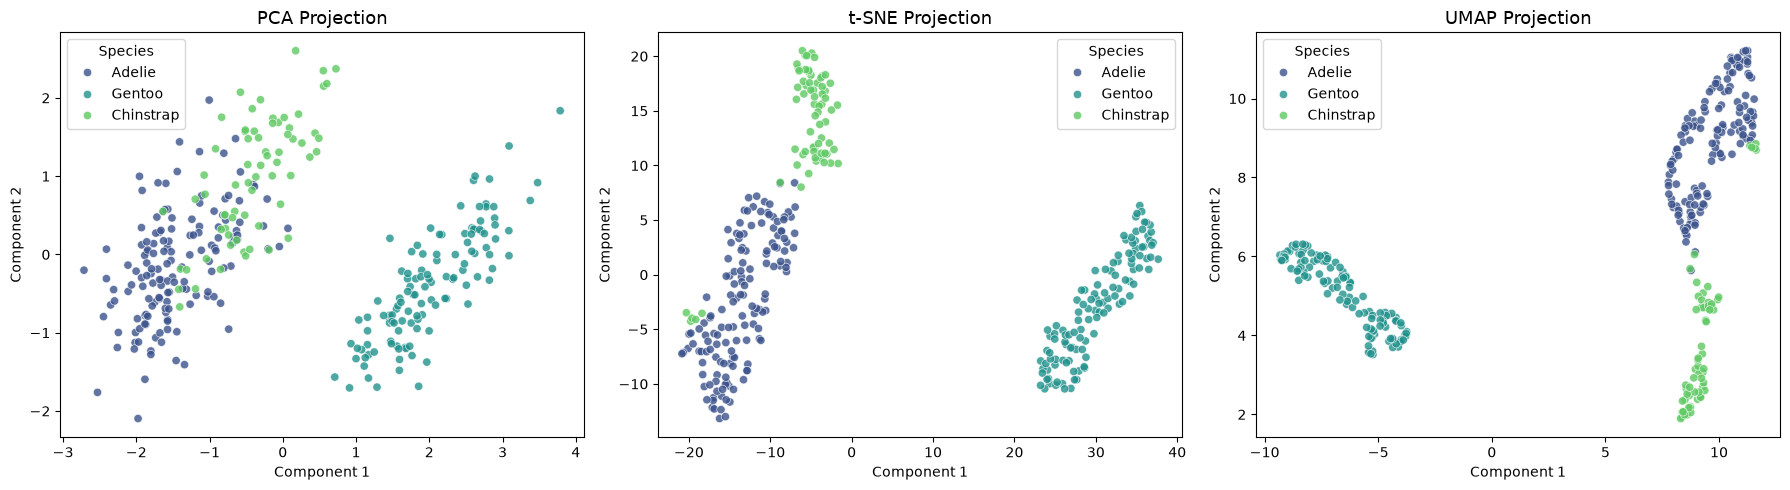

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

pca_embedding = PCA(n_components=2, random_state=42).fit_transform(scaled_features)
tsne_embedding = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(scaled_features)
umap_embedding = umap.UMAP(n_components=2, random_state=42).fit_transform(scaled_features)

reductions = {
    "PCA Projection": pca_embedding,
    "t-SNE Projection": tsne_embedding,
    "UMAP Projection": umap_embedding,
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (title, embedding) in zip(axes, reductions.items()):
    sns.scatterplot(
        x=embedding[:, 0],
        y=embedding[:, 1],
        hue=penguins_clean[target],
        palette="viridis",
        alpha=0.8,
        ax=ax
    )
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.legend(title="Species")

plt.tight_layout()
plt.show()

c. Analyze the resulting plots and describe the main patterns you observe.

- Which method produces the most visually separable clusters?
- Are there any species that overlap in one method but not in others?
- What might explain these differences in how the data is projected?

Elaborate on your observations and compare the strengths and limitations of each method based on this toy example.


Both the t-SNE and UMAP projections show visually seperable clusters, but UMAP seems to show the tightest clusters and seperations. Adelie and chinstrap overlap, in varying amounts, on all projection graphs, but gentoo remains relatively far and does not overlap with the other species. However, there are not two distinct clusters between Adelie and Chinstrap penguins in the PCA projection, while there is a clear general separation between all penguin clusters in the t-SNE and UMAP projections. PCA is linear and the other two are not, so t-SNE and UMAP are better at mapping non-linear relationships. In the UMAP projection, each cluster is packed tigher together than in the t-SNE projection. This is a byproduct of UMAPS `min_dist` hyperparameter which controls how tightly points can cluster. A t-SNE projection does not have this hyperparameter.

d. For **t-SNE** and **UMAP**, explore how different hyperparameter settings affect the resulting 2D projections.

- For **t-SNE**, vary the `perplexity` parameter (e.g., 5, 30, 50).
- For **UMAP**, vary the `n_neighbors` parameter (e.g., 5, 15, 50) and optionally `min_dist`.
- Keep `random_state` fixed across all runs so that differences between projections are due primarily to changes in the hyperparameters rather than random initialization.

For each configuration:
- Plot the resulting 2D projection.
- Use color to represent species.

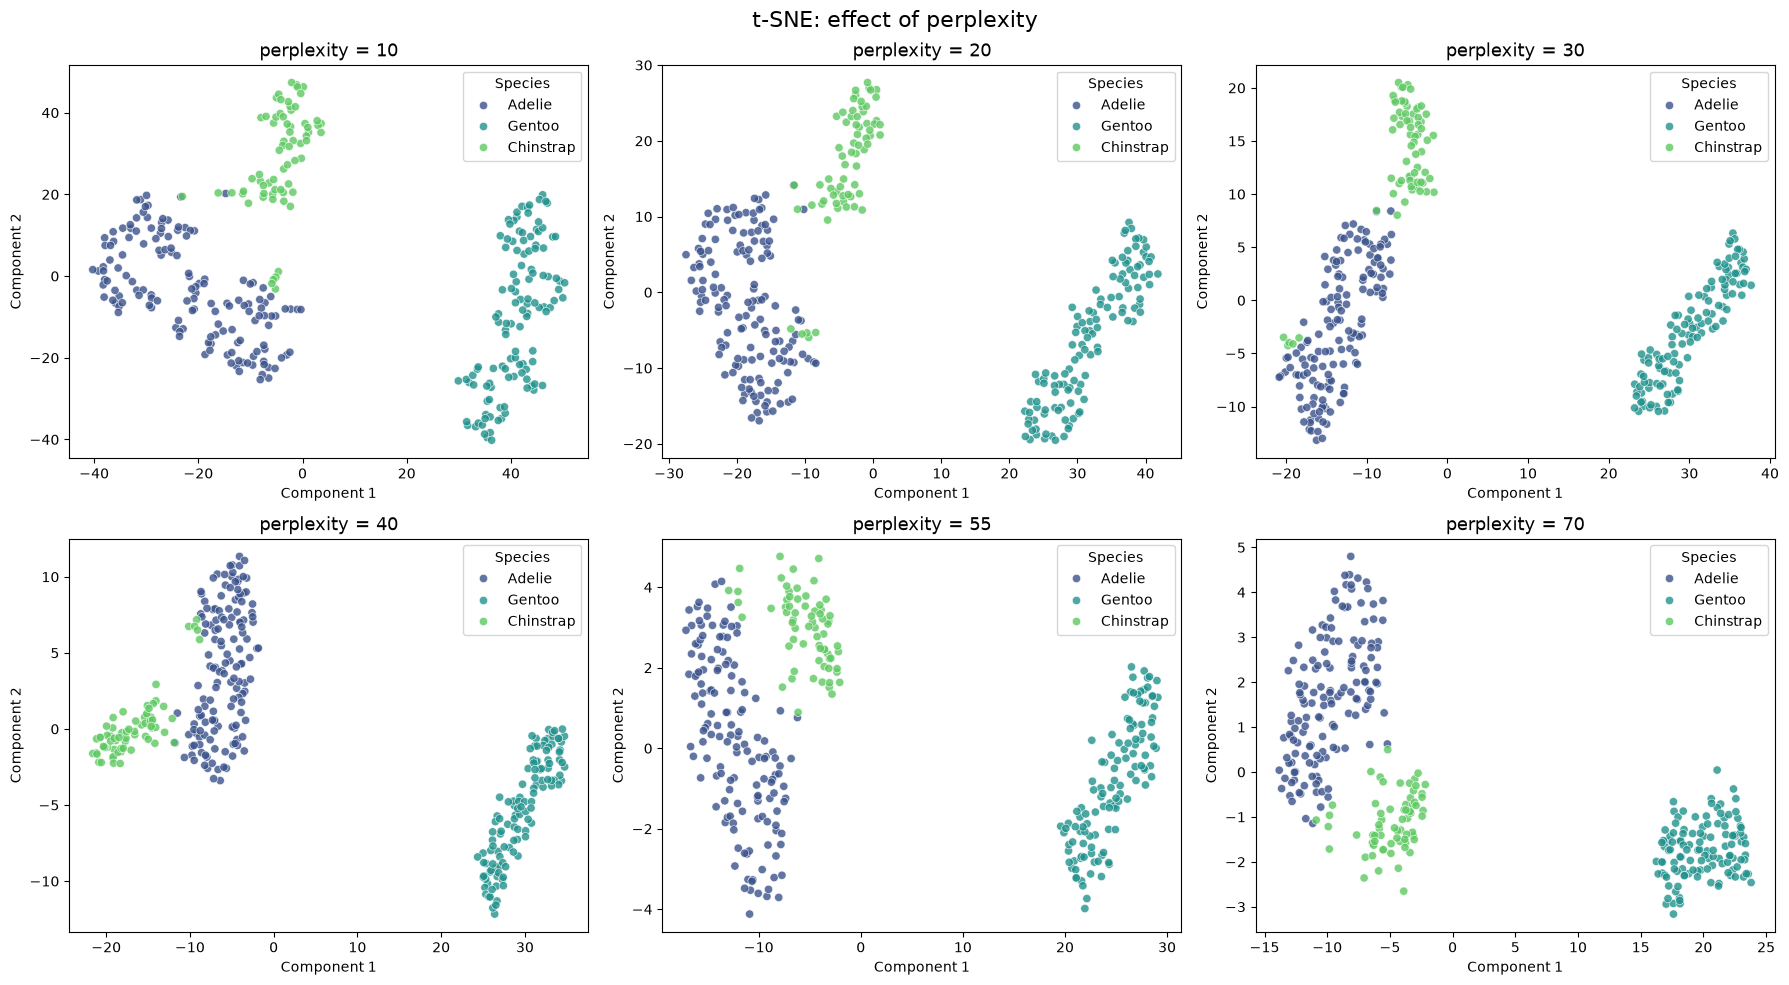

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import product
from sklearn.manifold import TSNE
import umap

# t-SNE: vary the perplexity
 
perplexities = [10, 20, 30, 40, 55, 70]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, p in zip(axes.flatten(), perplexities):
    emb = TSNE(n_components=2, perplexity=p, random_state=42).fit_transform(scaled_features)
    sns.scatterplot(
        x=emb[:, 0],
        y=emb[:, 1],
        hue=penguins_clean[target],
        palette="viridis",
        alpha=0.8,
        ax=ax
    )
    ax.set_title(f"perplexity = {p}", fontsize=13)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.legend(title="Species")

fig.suptitle("t-SNE: effect of perplexity", fontsize=16)
plt.tight_layout()
plt.show()


/Users/maxguryan/Desktop/DS/DS4021/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/maxguryan/Desktop/DS/DS4021/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/maxguryan/Desktop/DS/DS4021/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/maxguryan/Desktop/DS/DS4021/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/maxguryan/Desktop/DS/DS4021/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/maxguryan/Des

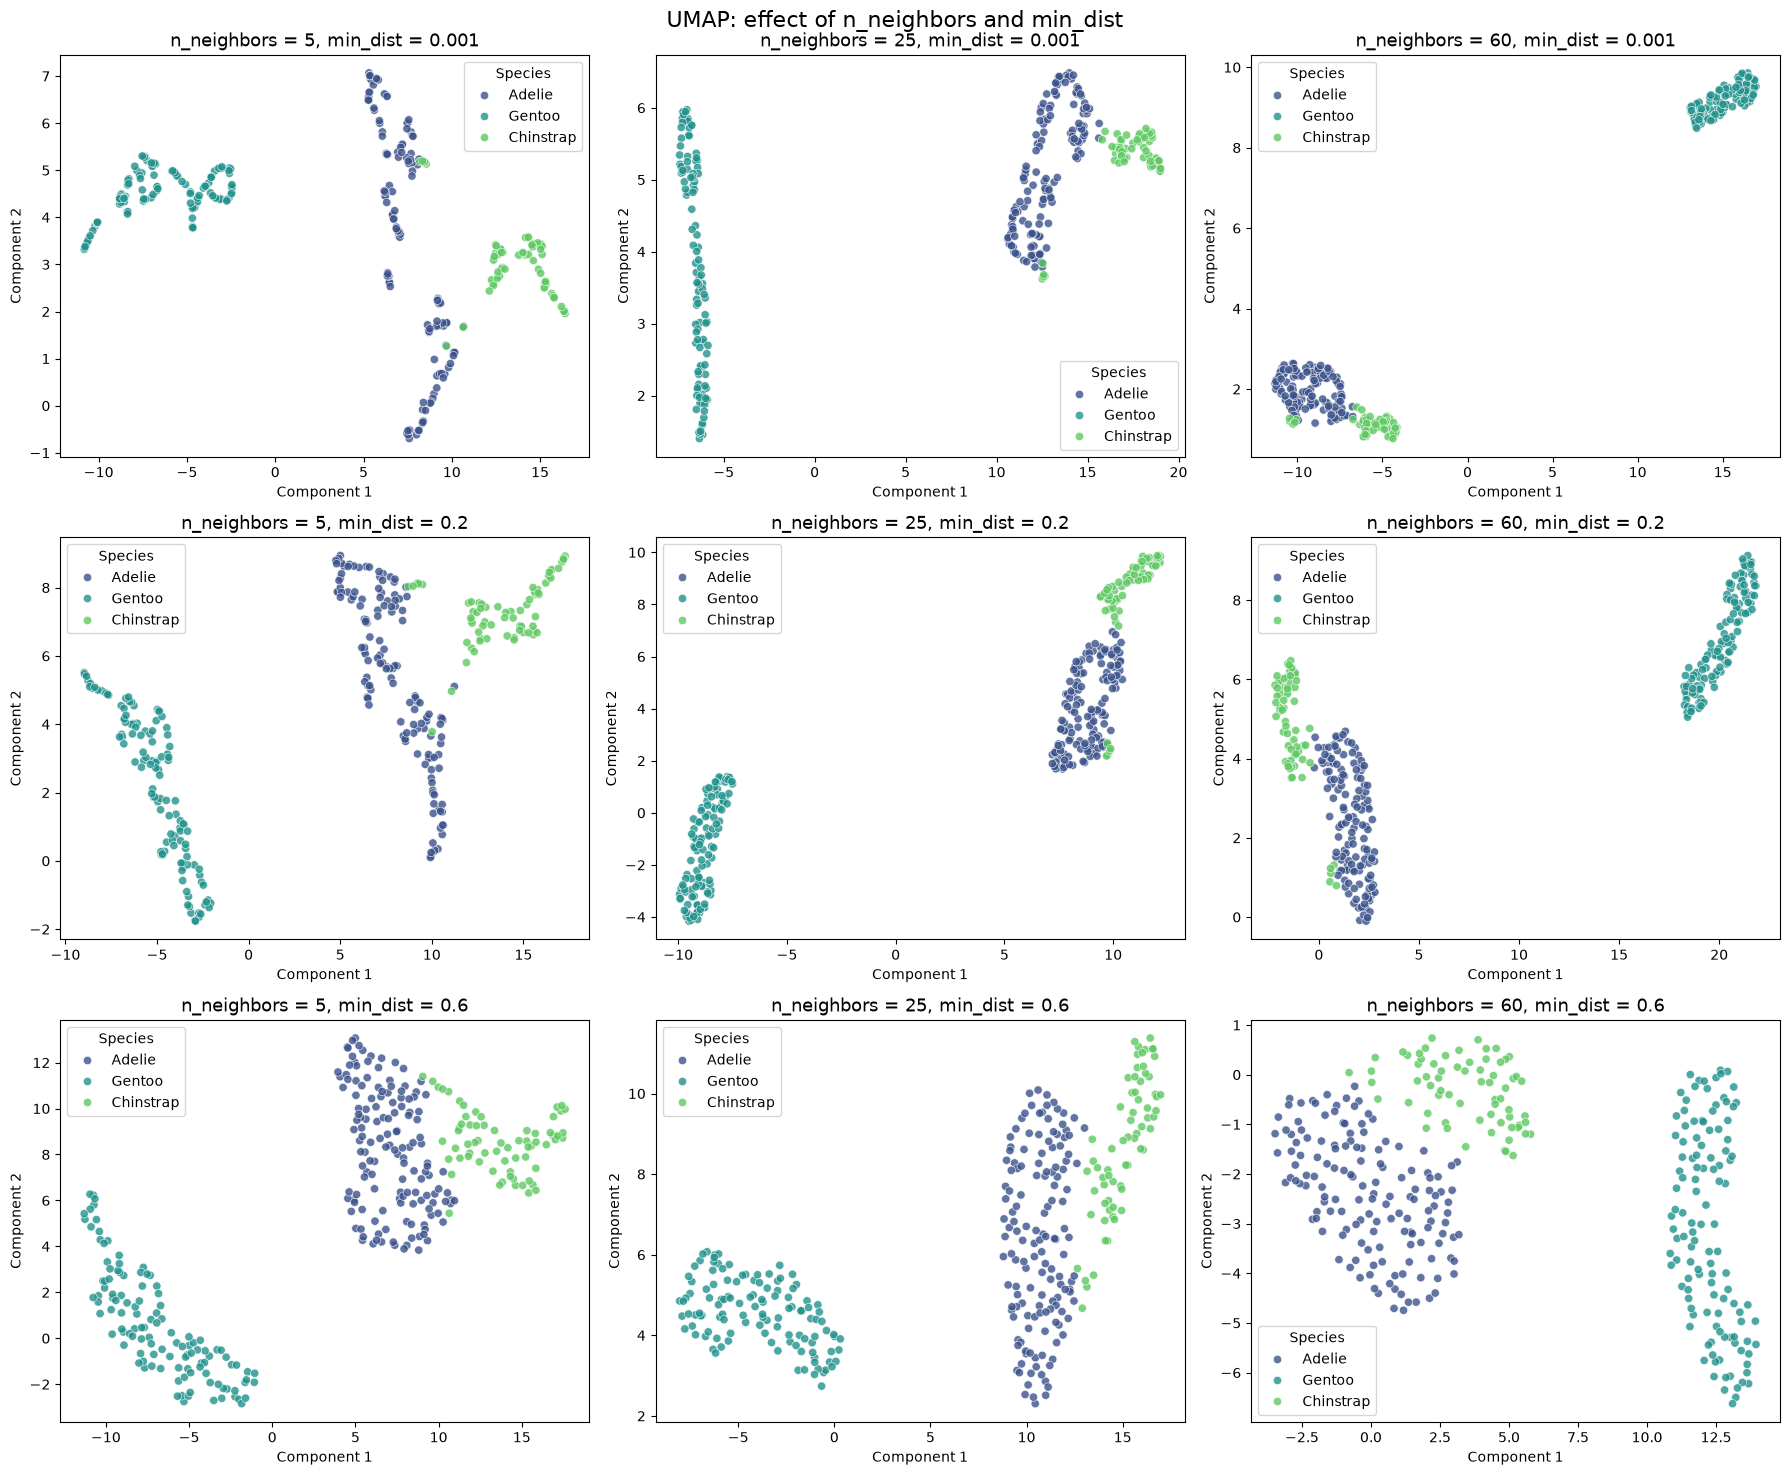

In [17]:
# UMAP: vary min_dist (rows) x n_neighbors (columns)
min_dists = [0.001, 0.2, 0.6]
neighbors = [5, 25, 60]
configs = list(product(min_dists, neighbors)) 

fig, axes = plt.subplots(len(min_dists), len(neighbors), figsize=(18, 15))

for ax, (md, n) in zip(axes.flatten(), configs):
    emb = umap.UMAP(n_components=2, n_neighbors=n, min_dist=md, random_state=42).fit_transform(scaled_features)
    sns.scatterplot(
        x=emb[:, 0],
        y=emb[:, 1],
        hue=penguins_clean[target],
        palette="viridis",
        alpha=0.8,
        ax=ax
    )
    ax.set_title(f"n_neighbors = {n}, min_dist = {md}", fontsize=13)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.legend(title="Species")

fig.suptitle("UMAP: effect of n_neighbors and min_dist", fontsize=16)
plt.tight_layout()
plt.show()

After generating the plots, describe the main changes you observe in the visualizations:
- How do the clusters shift, stretch, or separate as hyperparameters change?
- Which settings appear to better preserve the structure of the data?

Elaborate on your observations and support your discussion with specific visual examples.

#### t-SNE
As the perplexity hyperparameter increases, the scope of the model becomes more global when considering each point. In the beginning, as the perplexity increases, each cluster begins to get tighter and the separation becomes more clear. However, once perplexity ≥ 40 the model begins to break. The general orientation of the Adelie and Chinstrap clusters begins to shift and the clusters begin to separate again. The scope of the projection model begins to become too global, which is not something a t-SNE projection is built to handle, hindering the model's accuracy. A perplexity of around 30 seems to better preserve the structure of the data. 

#### UMAP
For this model, we considered a combination of n_neighbors and min_dist. Starting with n_neighbors, as this hyperparameter increases, the three clusters begin to separate into more profound groups. However, using n_neighbors = 60 as an example, if this hyperparameter value gets too large, the clusters shift orientation and begin to spread out, meaning the projection model is no longer preserving the structure of the data. Based on the three n_neighbors values we chose, n_neighbors = 25 seems to preserve the structure of the data the best because the original orientation of the three penguin clusters in still intact and there is the clearest visual separation between the Adelie and Chinstrap species. Moving onto min_dist, as the min_dist hyperparameter increases, the separation and shape of the clusters begin to increase and round out, making the clusters easier to visualize. However, if the min_dist becomes too large, the clusters become too spread out and overlap with the other clusters. Based on the three min_dist values we chose, min_dist = 0.2 seems to preserve the structure of the data the best because the original orientation of hte three penguin clusters is still intact and the clusters are still tightly bound together, unlike the min_dist = 60 subplots. Combining these two hyperparameters, n_neighbors = 25 and min_dist = 0.2, into one plot, the product is clusters that are tightly bound together, easily distinguishable from eachother with minimal overlap, and lacking the halucination of overintensified parameters. This combination appears to best preserve the structure of the data.


## 3. Apply to Real Data (1000 Genomes Subset) (25 points)

Your goal in this section is to try to create a figure similar to Figure 1 of the Diaz-Papkovich *et al.* (2019) paper, using a subset of genotype data from the 1000 Genomes Project.

To do so, complete the following steps:

a. Load the genotype dataset accompanying this lab, where each row corresponds to an individual, and each column to a genetic variant. Load also the provided population labels for each individual. 

b. **Standardize** the features (i.e., transform the genotype values to have zero mean and unit variance).

c. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the data to 2 dimensions. You may use the default values for the rest of hyperparameters in these techniques. 

d. Create **scatter plots** of the resulting projections, coloring each point according to its **population group**.

e. Reflect on the following questions:
- Explain what you observe in each case. Additionally, which method appears to provide the best visual separation of the population into distinct groups? Elaborate on why this might be the case, based on what you know about each method.
- What changes if you first reduce the data to the **top 25 PCA components**, and then apply t-SNE or UMAP?
- In your opinion, what are the trade-offs between **interpretability** (e.g., preservation of local and global structure) and **performance** (e.g., visual separation of known populations and computational time) when using these dimensionality reduction methods?

Please elaborate on your answers and use the plots to support your discussion.

In [21]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

#a
X = np.load('genome_data_lab3.npy')
labels = np.loadtxt('population_labels_lab3.txt', dtype=str)

#First 5 individuals and first 5 variants
print("\nFirst 5 rows and 5 columns of X:")
print(X[:5, :5])

#First few labels
print("\nFirst 10 population labels:")
print(labels[:10])

#b
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


First 5 rows and 5 columns of X:
[[0 1 1 2 1]
 [0 1 2 1 0]
 [0 2 1 0 1]
 [2 2 1 1 0]
 [1 2 1 0 0]]

First 10 population labels:
['GBR' 'GBR' 'GBR' 'GBR' 'GBR' 'GBR' 'GBR' 'GBR' 'GBR' 'GBR']


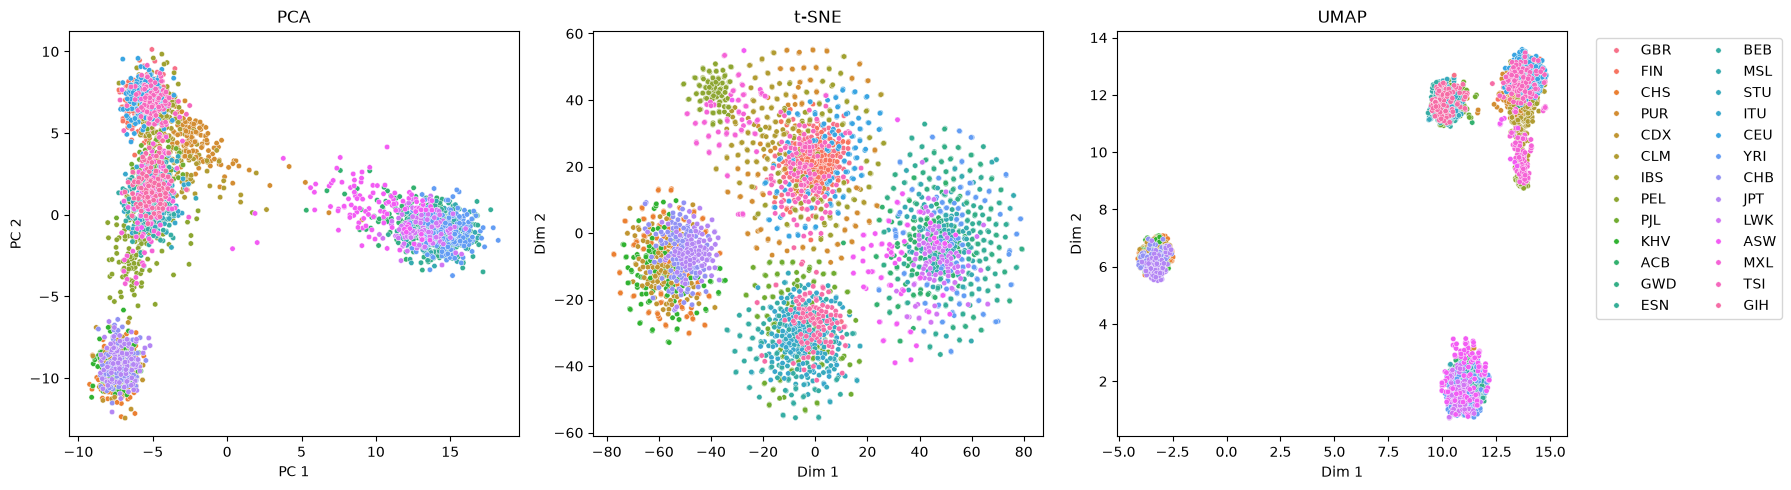

In [22]:
# c
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

tsne = TSNE(n_components=2)
X_tsne = tsne.fit_transform(X_scaled)

reducer = umap.UMAP(n_components=2)
X_umap = reducer.fit_transform(X_scaled)

# d
plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, legend=False, s=15)
plt.title('PCA')
plt.xlabel('PC 1')
plt.ylabel('PC 2')

plt.subplot(1, 3, 2)
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=labels, legend=False, s=15)
plt.title('t-SNE')
plt.xlabel('Dim 1')
plt.ylabel('Dim 2')

plt.subplot(1, 3, 3)
sns.scatterplot(x=X_umap[:, 0], y=X_umap[:, 1], hue=labels, s=15)
plt.title('UMAP')
plt.xlabel('Dim 1')
plt.ylabel('Dim 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)

plt.tight_layout()
plt.show()

## 4. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

Our group did not encounter any major problems during this lab. As a group, we did a great job communicating with one another, equitably splitting up the tasks, staying on top of our agreed deadlines, and sharing feedback when needed. We improved upon our problem of doing the majority of the work on our own time, as we managed to achieve a lot togtehr during the lab session. That said,